In [28]:
import pandas as pd
import numpy as np

In [29]:
data=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [30]:
data

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [31]:
df=data[['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']]

In [32]:
df

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0
...,...,...,...,...,...
9995,2470,271.0,4690,2005,27.4
9996,2300,244.0,4370,1993,30.0
9997,2480,267.0,4590,2014,28.1
9998,2180,270.0,4450,2004,32.2


In [33]:
import matplotlib.pyplot as plt
import seaborn as sns 

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

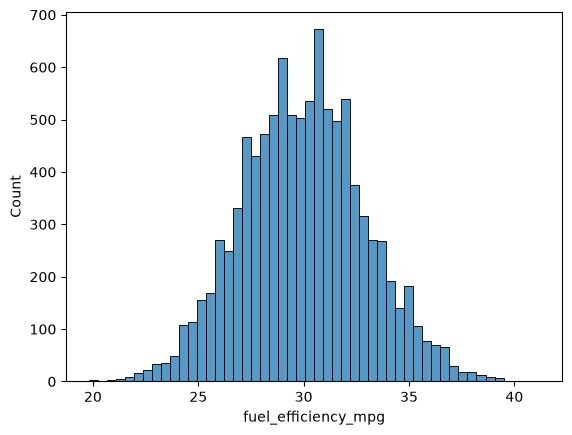

In [34]:
sns.histplot(df['fuel_efficiency_mpg'], bins= 50)

In [35]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [36]:
df['horsepower'].median()

np.float64(254.0)

In [37]:
n=len(df)

In [38]:
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_val-n_test

In [39]:
np.random.seed(42)
idx=np.arange(n)

np.random.shuffle(idx)

df_train=df.iloc[idx[:n_train]]
df_val=df.iloc[idx[n_train:n_train+n_val]]
df_test=df.iloc[idx[n_train+n_val:]]

In [40]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)

In [41]:
y_train=df_train.fuel_efficiency_mpg.values
y_val=df_val.fuel_efficiency_mpg.values
y_test=df_test.fuel_efficiency_mpg.values

In [42]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

Option : 1 Filling the missing values with zero.

In [43]:
# train_linear_regression
X_train=df_train.fillna(0).values

In [44]:
X_train

array([[1900.,  239., 3790., 2015.],
       [2000.,  224., 4380., 1992.],
       [2330.,  286., 4090., 2022.],
       ...,
       [2240.,  255., 4190., 1989.],
       [2430.,  254., 4280., 2020.],
       [2390.,  266., 4220., 1996.]], shape=(6000, 4))

In [45]:
def train_linear_regression(X,y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    
    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    
    w_full= XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]
    

In [46]:
w0,w=train_linear_regression(X_train,y_train)

In [47]:
w0,w

(np.float64(-153.88496188223104),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]))

In [48]:
y_pred= w0+ X_train.dot(w)

In [49]:
y_pred

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172], shape=(6000,))

In [50]:
def rmse(y,y_pred):
    error= y-y_pred
    error=error**2
    mse=error.mean()
    
    return np.sqrt(mse).round(3)
    

In [51]:
rmse(y_train,y_pred)

np.float64(2.2)

rmse on validating data

In [52]:
x_val=df_val.fillna(0).values

In [53]:
x_val

array([[2240.,  265., 3990., 2004.],
       [2390.,  259., 4770., 2019.],
       [2360.,  265., 4320., 2018.],
       ...,
       [2390.,  264., 4550., 2017.],
       [2330.,  244., 4440., 2014.],
       [2170.,  260., 4460., 2021.]], shape=(2000, 4))

In [54]:
y_val_pred=w0+ x_val.dot(w)

In [55]:
rmse(y_val,y_val_pred)

np.float64(2.205)

replacing the values with mean

In [56]:
x_mean=df_train.fillna(df_train['horsepower'].mean().round(3)).values

In [57]:
w0,w=train_linear_regression(x_mean,y_train)

In [58]:
y_pred_mean=w0+x_mean.dot(w)

In [59]:
rmse(y_train,y_pred_mean)

np.float64(2.198)

In [60]:
x_val=df_val.fillna(df_val['horsepower'].mean().round(3)).values
y_pred_mean_val=w0+x_val.dot(w)
rmse(y_val,y_pred_mean_val)

np.float64(2.202)

 Regularization 

In [97]:
def preparex(X):
    X=X.copy()
    X=X.fillna(0).values
    
    
    return X
    

In [96]:
def train_linear_regression_reguarized(X, y, r):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    
    XTX=X.T.dot(X)
    XTX=XTX + r* np.eye(XTX.shape[0])
    
    XTX_inv=np.linalg.inv(XTX)
    
    w_full= XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]
    

In [106]:
X_train=preparex(df_train)

In [117]:
w0,w=train_linear_regression_reguarized(X_train,y_train,r=0)

In [118]:
w0,w

(np.float64(-153.88496188223104),
 array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01]))

In [119]:
x_val=preparex(df_val)

In [120]:
y_pred_regularized= w0 + x_val.dot(w)

In [121]:
rmse(y_val,y_pred_regularized)

np.float64(2.205)

question 5:

In [130]:
def quest_5(df):
    
    score=[]

    for s in range(0,10):
        np.random.seed(s)
    
        n=len(df)
        n_val=int(n*0.2)
        n_test=int(n*0.2)
        n_train= n-n_val-n_test
        
        df=df.copy()
        
        idx=np.arange(n)
        np.random.shuffle(idx)
        
        df_train=df.iloc[idx[:n_train]]
        df_val=df.iloc[idx[n_train:n_train+n_val]]
        df_test=df.iloc[idx[n_train+n_val:]]
        
        y_train=df_train.fuel_efficiency_mpg.values
        y_val=df_val.fuel_efficiency_mpg.values
        y_test=df_test.fuel_efficiency_mpg.values
        
        del df_train['fuel_efficiency_mpg']
        del df_val['fuel_efficiency_mpg']
        del df_test['fuel_efficiency_mpg']
        
        X=preparex(df_train)
        w0, w= train_linear_regression(X,y_train)
        
        x_val=preparex(df_val)
        y_pred=w0 +x_val.dot(w)
        
        mpg=rmse(y_val, y_pred)
        score.append(mpg)
        
    return score  

In [131]:
abc=quest_5(df)

In [135]:
np.round(np.std(abc),3)

np.float64(0.029)

Question 6

In [136]:
def quest_6(df):

    
    n=len(df)
    n_val=int(n*0.2)
    n_test=int(n*0.2)
    n_train= n-n_val-n_test
    
    df=df.copy()
    
    np.random.seed(9)
    idx=np.arange(n)
    np.random.shuffle(idx)
    
    df_train=df.iloc[idx[:n_train]]
    df_val=df.iloc[idx[n_train:n_train+n_val]]
    df_test=df.iloc[idx[n_train+n_val:]]
    
    y_train=df_train.fuel_efficiency_mpg.values
    y_val=df_val.fuel_efficiency_mpg.values
    y_test=df_test.fuel_efficiency_mpg.values
    
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']
    
    df_full_train = pd.concat([df_train, df_val])
    df_full_train = df_full_train.reset_index(drop=True)
    X=preparex(df_full_train)
    
    
    y_full_train = np.concatenate([y_train, y_val])
    
    w0, w= train_linear_regression_reguarized(X,y_full_train, r=0.001)
    
    x_test=preparex(df_test)
    y_pred=w0 +x_test.dot(w)
    
    score=rmse(y_test, y_pred)
        
    return score  

In [137]:
question_6=quest_6(df)
question_6

np.float64(2.236)